# Accuracy Breakdown — Physical Occluded Subset

Overall accuracy for each model on the **physical occlusion** test.

Results are shown under three scoring systems: **GPT-only**, **Claude-only**, and **Combined** (average of both judges).

In [ ]:
# Run from the repo root so the root-relative data paths below resolve
import os
from pathlib import Path
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sec3_occludebench").is_dir()))

In [1]:
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

RESULTS_DIR = 'data/eval_results_physical'
ANNOTATIONS_PATH = 'data/combined_output/annotations.json'

MODEL_STEMS = [
    'gpt-5.4',
    'claude-opus-4-6',
    'gemini-3.1-pro-preview',
    'Qwen3-VL-8B-Instruct',
    'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c',
]

DISPLAY_NAMES = {
    'gpt-5.4': 'GPT-5.4',
    'claude-opus-4-6': 'Claude Opus 4.6',
    'gemini-3.1-pro-preview': 'Gemini 3.1 Pro',
    'Qwen3-VL-8B-Instruct': 'Qwen3-VL 8B',
    'Llama-4-Maverick-17B-128E-Instruct-FP8-9940db5c': 'Llama-4 Maverick 17B',
}

SCORING_SYSTEMS = {
    'GPT-only':    ['gpt-5.4'],
    'Claude-only': ['claude-opus-4-6'],
    'Combined':    ['gpt-5.4', 'claude-opus-4-6'],
}

In [2]:
with open(ANNOTATIONS_PATH) as f:
    annotations = json.load(f)

physical_map = {str(item['id']): item['physical'] for item in annotations}
print(f'Loaded {len(physical_map)} annotations')

Loaded 378 annotations


In [3]:
def compute_accuracy(judged_data, verdict_key, judge_models):
    correct = total = 0
    for item in judged_data:
        verdict_dict = item.get(verdict_key, {})
        if not isinstance(verdict_dict, dict):
            continue
        scores = [verdict_dict[jm] for jm in judge_models
                  if jm in verdict_dict and verdict_dict[jm] is not None]
        if not scores:
            continue
        correct += sum(scores) / len(scores)
        total += 1
    return correct / total * 100 if total > 0 else None


judged_cache = {}
for stem in MODEL_STEMS:
    path = os.path.join(RESULTS_DIR, f'{stem}_judged_results.json')
    if os.path.exists(path):
        with open(path) as f:
            judged_cache[stem] = json.load(f)
    else:
        print(f'Missing: {path}')

rows_by_scoring = {}
for scoring_name, judge_models in SCORING_SYSTEMS.items():
    rows = []
    for stem in MODEL_STEMS:
        if stem not in judged_cache:
            continue
        acc = compute_accuracy(judged_cache[stem], 'occluded_correct', judge_models)
        rows.append({'model': DISPLAY_NAMES[stem], 'accuracy': acc})
    rows_by_scoring[scoring_name] = pd.DataFrame(rows).set_index('model')

print('Done.')

Done.


---
## Summary Table

In [4]:
summary = pd.concat(
    [df.rename(columns={'accuracy': name}) for name, df in rows_by_scoring.items()],
    axis=1
)
display(summary.applymap(lambda x: f'{x:.1f}%' if x is not None else 'N/A'))

,GPT-only,Claude-only,Combined
model,,,
GPT-5.4,22.9%,22.9%,22.9%
Claude Opus 4.6,24.4%,26.7%,25.6%
Gemini 3.1 Pro,33.6%,31.3%,32.4%
Qwen3-VL 8B,6.1%,9.2%,7.6%
Llama-4 Maverick 17B,9.2%,10.7%,9.9%


---
## Accuracy Bar Chart

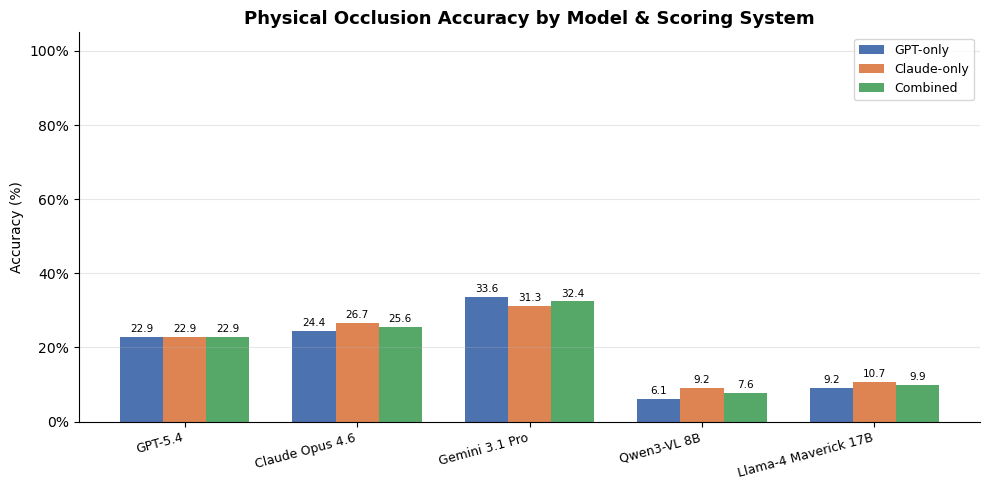

In [5]:
models = [DISPLAY_NAMES[s] for s in MODEL_STEMS if s in judged_cache]
x = np.arange(len(models))
width = 0.25
colors = ['#4C72B0', '#DD8452', '#55A868']

fig, ax = plt.subplots(figsize=(10, 5))

for i, (scoring_name, df) in enumerate(rows_by_scoring.items()):
    vals = [df.loc[m, 'accuracy'] if m in df.index else 0 for m in models]
    bars = ax.bar(x + (i - 1) * width, vals, width, label=scoring_name, color=colors[i])
    for bar, v in zip(bars, vals):
        if v is not None:
            ax.annotate(f'{v:.1f}',
                        xy=(bar.get_x() + bar.get_width() / 2, v),
                        xytext=(0, 2), textcoords='offset points',
                        ha='center', va='bottom', fontsize=7.5)

ax.set_title('Physical Occlusion Accuracy by Model & Scoring System',
             fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15, ha='right', fontsize=9)
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Accuracy (%)')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

In [6]:
summary_or = pd.concat(
    [df.rename(columns={'accuracy': name}) for name, df in rows_by_scoring.items()],
    axis=1
)
summary_or['Combined'] = summary_or[['GPT-only', 'Claude-only']].max(axis=1)
display(summary_or[['GPT-only', 'Claude-only', 'Combined']].applymap(lambda x: f'{x:.1f}%' if x is not None else 'N/A'))

,GPT-only,Claude-only,Combined
model,,,
GPT-5.4,22.9%,22.9%,22.9%
Claude Opus 4.6,24.4%,26.7%,26.7%
Gemini 3.1 Pro,33.6%,31.3%,33.6%
Qwen3-VL 8B,6.1%,9.2%,9.2%
Llama-4 Maverick 17B,9.2%,10.7%,10.7%
